In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install expecto pandas matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 59.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 984.6/984.6 kB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [expecto]



**PHOENIX Stellar Spectra: Machine Learning Classification Pipeline**

#Phase 1 : Trial Datasets for 16 Stars

##**Downloading PHOENIX Spectrum



        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.


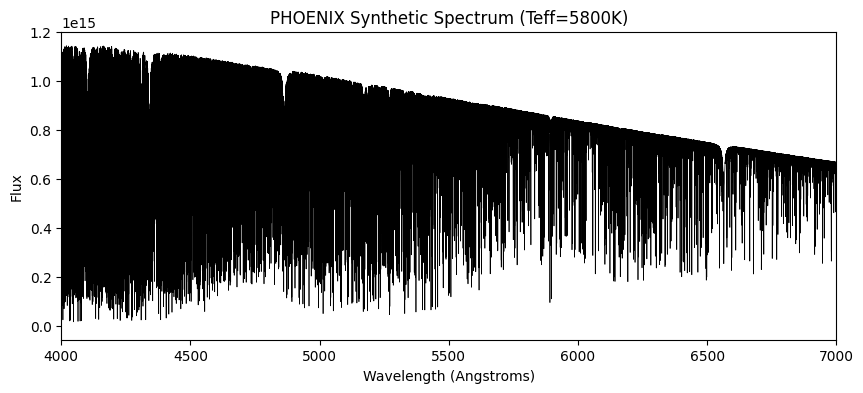

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from expecto import get_spectrum

# Download the spectrum
print("Downloading PHOENIX Spectrum...")
spectrum = get_spectrum(T_eff=5800, log_g=4.5, cache=False)

# Convert it to a Pandas DataFrame
df = pd.DataFrame({
    'wavelength': spectrum.wavelength.value,
    'flux': spectrum.flux.value
})

# Plot the visible light region
plt.figure(figsize=(10, 4))
plt.plot(df['wavelength'], df['flux'], color='black', linewidth=0.5)
plt.title('PHOENIX Synthetic Spectrum (Teff=5800K)')
plt.xlabel('Wavelength (Angstroms)')
plt.ylabel('Flux')
plt.xlim(4000, 7000)
plt.show()

## Step 1: Data Acquisition & Visible-Light Masking (4000Å - 7000Å)

In [ ]:
import pandas as pd
import numpy as np
from expecto import get_spectrum
import time

# 1. Define the grid of stars we want to simulate
# We will test 4 different temperatures and 4 different metallicities
temperatures = [5000, 5500, 6000, 6500]
metallicities = [-2.0, -1.0, 0.0, 0.5] # -2.0 is metal-poor, 0.0 is solar

dataset_rows = []
print("Building Machine Learning Dataset...")

# 2. Loop through every combination of temperature and metallicity
for teff in temperatures:
    for feh in metallicities:
        print(f"Downloading: Teff={teff}K, [Fe/H]={feh}...")

        # 'z' represents the metallicity parameter [Fe/H] in the PHOENIX grid
        spectrum = get_spectrum(T_eff=teff, log_g=4.5, Z=feh, cache=False)

        # 3. Filter for visible light (4000 to 7000 Angstroms)
        mask = (spectrum.wavelength.value >= 4000) & (spectrum.wavelength.value <= 7000)
        visible_wave = spectrum.wavelength.value[mask]
        visible_flux = spectrum.flux.value[mask]

        # 4. Downsample the data (take every 100th data point)
        # High-res spectra have millions of points. Downsampling prevents Colab RAM crashes.
        downsampled_wave = visible_wave[::100]
        downsampled_flux = visible_flux[::100]

        # 5. Create a dictionary row where the target label is Metallicity
        row = {'T_eff': teff, 'Metallicity_Target': feh}

        # Add the flux values as input features (X variables) for the ML model
        for w, f in zip(downsampled_wave, downsampled_flux):
            row[f'flux_at_{w:.1f}'] = f

        dataset_rows.append(row)
        time.sleep(1) # Pause for 1 second to avoid overloading the server

# 6. Convert the nested data into a Pandas DataFrame and save it
df_ml = pd.DataFrame(dataset_rows)
df_ml.to_csv('/content/drive/MyDrive/phoenix_ml_dataset.csv', index=False)

print(f"\nDataset generation complete! Matrix shape: {df_ml.shape}")
print("Saved to: /content/drive/MyDrive/phoenix_ml_dataset.csv")

Building Machine Learning Dataset...
Downloading: Teff=5000K, [Fe/H]=-2.0...


        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.


Downloading: Teff=5000K, [Fe/H]=-1.0...


        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.


Downloading: Teff=5000K, [Fe/H]=0.0...


...

Downloading: Teff=6500K, [Fe/H]=0.0...


        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.


Downloading: Teff=6500K, [Fe/H]=0.5...


        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.



Dataset generation complete! Matrix shape: (16, 3669)
Saved to: /content/drive/MyDrive/phoenix_ml_dataset.csv


## Step 2: Dimensionality Reduction via Principal Component Analysis (PCA)

Loading dataset for PCA...
Original shape: (16, 3667) (3667 features)
New compressed shape: (16, 5) (5 features)


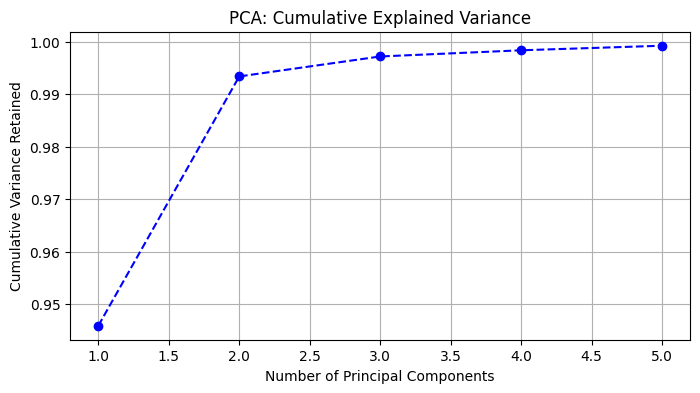

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Loading dataset for PCA...")
# 1. Load the dataset you just created
df_ml = pd.read_csv('/content/drive/MyDrive/phoenix_ml_dataset.csv')

# 2. Separate the Target (what we want to predict) from the Features (the clues)
# We want to predict Metallicity. We drop T_eff because we want the model to learn
# from the spectrum itself, not cheat by looking at the temperature label.
y = df_ml['Metallicity_Target']
X = df_ml.drop(columns=['Metallicity_Target', 'T_eff'])

# 3. Standardize the data
# Machine learning algorithms need all numbers to be on the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply Principal Component Analysis (PCA)
# We will compress the 3667 wavelengths down into just 5 core components
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

# 5. Evaluate how much information we retained
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)

print(f"Original shape: {X.shape} (3667 features)")
print(f"New compressed shape: {X_pca.shape} (5 features)")

# 6. Plot the Cumulative Variance
plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), cumulative_variance, marker='o', linestyle='--', color='blue')
plt.title('PCA: Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Retained')
plt.grid(True)
plt.show()

## Step 3: Bayesian Model Training & Confusion Matrix Validation

Initializing Milestone 3: Model Training...
Model training complete.
Model Accuracy on Blind Test Set: 75.00%



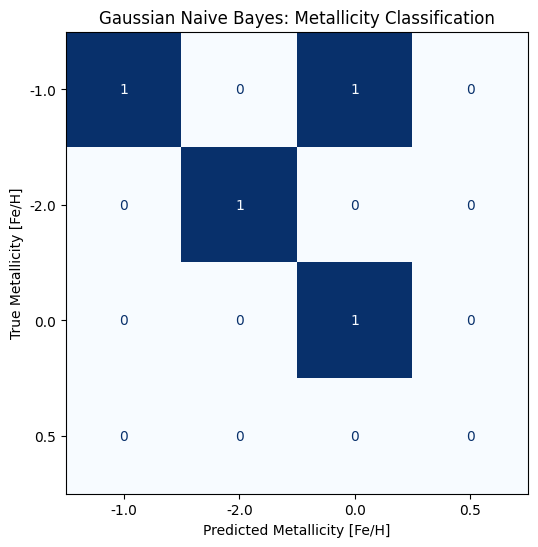

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Initializing Milestone 3: Model Training...")

# THE FIX: Convert the decimal numbers into categorical strings so scikit-learn knows it is a classification task
y_categorical = y.astype(str)

# 1. Split the data using the new categorical labels
X_train, X_test, y_train, y_test = train_test_split(X_pca, y_categorical, test_size=0.25, random_state=42)

# 2. Initialize the Bayesian Machine Learning Model
model = GaussianNB()

# 3. Train (Fit) the model using the 12 study guide stars
model.fit(X_train, y_train)
print("Model training complete.")

# 4. Give the model the 4 test stars (clues only) and force it to make predictions
y_predictions = model.predict(X_test)

# 5. Calculate how accurate the predictions were against the real answers
accuracy = accuracy_score(y_test, y_predictions)
print(f"Model Accuracy on Blind Test Set: {accuracy * 100:.2f}%\n")

# 6. Plot the Confusion Matrix to visualize the performance
cm = confusion_matrix(y_test, y_predictions, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Gaussian Naive Bayes: Metallicity Classification')
plt.xlabel('Predicted Metallicity [Fe/H]')
plt.ylabel('True Metallicity [Fe/H]')
plt.show()

# Phase 2: Scaling the Pipeline to a 100-Star Grid



## Step 1: Data Acquisition & Visible-Light Masking (4000Å - 7000Å)
To construct the core dataset, we programmatically query the PHOENIX synthetic spectral grid across a parameter space of 100 distinct stars. The extracted spectra are masked to the visible light domain (4000Å - 7000Å) to isolate critical atomic absorption lines and downsampled to optimize computational memory before modeling.

In [9]:
import pandas as pd
import time
from expecto import get_spectrum

# 1. Expanded Grid: 10 Temperatures and 10 Metallicities = 100 Stars
temperatures = [4000, 4500, 5000, 5500, 6000, 6500, 7000, 7500, 8000, 8500]
metallicities = [-3.0, -2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5]

dataset_rows = []
print("Building Scaled Machine Learning Dataset (100 Stars)...")

for teff in temperatures:
    for feh in metallicities:
        try:
            spectrum = get_spectrum(T_eff=teff, log_g=4.5, Z=feh, cache=False)

            mask = (spectrum.wavelength.value >= 4000) & (spectrum.wavelength.value <= 7000)
            visible_wave = spectrum.wavelength.value[mask]
            visible_flux = spectrum.flux.value[mask]

            # Downsampling by 100 to prevent RAM overload
            downsampled_wave = visible_wave[::100]
            downsampled_flux = visible_flux[::100]

            row = {'T_eff': teff, 'Metallicity_Target': feh}
            for w, f in zip(downsampled_wave, downsampled_flux):
                row[f'flux_at_{w:.1f}'] = f

            dataset_rows.append(row)
            time.sleep(1) # Prevent server timeout
        except Exception as e:
            # If a specific star combination doesn't exist in PHOENIX, skip it
            pass

df_ml_scaled = pd.DataFrame(dataset_rows)
df_ml_scaled.to_csv('/content/drive/MyDrive/phoenix_ml_dataset_100.csv', index=False)
print(f"\nScaled Dataset complete! New Matrix shape: {df_ml_scaled.shape}")

Building Scaled Machine Learning Dataset (100 Stars)...


        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum instead. [expecto.core]
        Use Spectrum instead.
        Use Spectrum inst


Scaled Dataset complete! New Matrix shape: (100, 3669)


## Step 2 : Dimensionality Reduction via Principal Component Analysis (PCA)
To resolve the Curse of Dimensionality and isolate the core atomic absorption signatures, we standardize the spectral flux vectors and compress the thousands of wavelength features down to 10 principal components.

In [11]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Loading 100-Star Dataset and executing PCA Compression...")

# 1. Load the expanded dataset
df_scaled = pd.read_csv('/content/drive/MyDrive/phoenix_ml_dataset_100.csv')

# 2. Separate Features (X) and Target (y)
y_scaled = df_scaled['Metallicity_Target'].astype(str)
X_scaled_raw = df_scaled.drop(columns=['Metallicity_Target', 'T_eff'])

# 3. Standardize the data
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X_scaled_raw)

# 4. Apply PCA Compression
pca = PCA(n_components=10)
X_pca_scaled = pca.fit_transform(X_standardized)

print(f"Successfully compressed {X_scaled_raw.shape[1]} wavelengths into 10 principal components.")
print(f"Final PCA Matrix Shape: {X_pca_scaled.shape}")

Loading 100-Star Dataset and executing PCA Compression...
Successfully compressed 3667 wavelengths into 10 principal components.
Final PCA Matrix Shape: (100, 10)


## Step 3: Bayesian Model Training & Confusion Matrix Validation
Aligning with the statistical methodologies utilized in the 4MOST survey, we deploy a Gaussian Naive Bayes classifier. The dataset is partitioned into a 75/25 Train-Test split to rigorously evaluate algorithmic accuracy on blind test stars.

Initializing Gaussian Naive Bayes Training...

FINAL MODEL ACCURACY on 25 Blind Test Stars: 20.00%



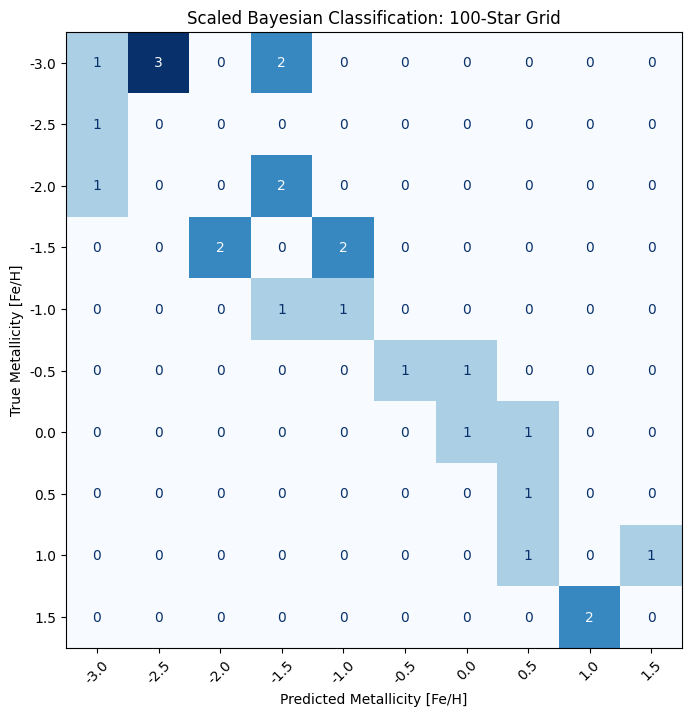

In [13]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Initializing Gaussian Naive Bayes Training...")

X_train, X_test, y_train, y_test = train_test_split(
    X_pca_scaled, y_scaled, test_size=0.25, random_state=42
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nFINAL MODEL ACCURACY on 25 Blind Test Stars: {accuracy * 100:.2f}%\n")

# THE FIX: We explicitly tell Python the correct mathematical order for the labels
correct_order = ['-3.0', '-2.5', '-2.0', '-1.5', '-1.0', '-0.5', '0.0', '0.5', '1.0', '1.5']

cm = confusion_matrix(y_test, y_pred, labels=correct_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=correct_order)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Scaled Bayesian Classification: 100-Star Grid')
plt.xlabel('Predicted Metallicity [Fe/H]')
plt.ylabel('True Metallicity [Fe/H]')
plt.xticks(rotation=45)
plt.show()